* NAME: PATHIKRITH BANERJEE
* Student ID: 0842BBUN
* Module: 6FTC2175: Advanced Machine Learning and Neural Network
* Affiliation: University of Hertfordshire

Part A - Representation Learning (Trains)
Using a train sensor dataset:

• Apply PCA to reduce the dimensionality of the data and visualise it in two dimensions.

• Build and train a linear autoencoder on the same data and compare the representation it learns with the PCA projection.

• Optionally, apply a Self-Organising Map to the data for clustering and/or visualisation, and compare its output with PCA/the autoencoder.

Interpret your results: what structure (for example normal operation versus a developing fault) does each method reveal about the data?


DATASET SELECTION:

* MetroPT-3 was selected for Part A because its multivariate train sensor measurements provide a suitable basis for comparing linear dimensionality-reduction methods and investigating operational patterns.



In [ ]:

import os
import pandas as pd
import numpy as np

from google.colab import drive
drive.mount('/content/drive')

# Dataset location
DATA_PATH = "/content/drive/MyDrive/AMLNN_AS2/Metro.csv"

# Verify file exists
assert os.path.exists(DATA_PATH), f"Dataset not found: {DATA_PATH}"

# Load dataset
df = pd.read_csv(DATA_PATH)

print("=" * 60)
print("AMLNN ASSIGNMENT 2 — PART A: METROPT-3")
print("=" * 60)

print("\nDataset dimensions:")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five observations:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nNumerical summary:")
display(df.describe())


Mounted at /content/drive
AMLNN ASSIGNMENT 2 — PART A: METROPT-3

Dataset dimensions:
Rows: 1,516,948
Columns: 17

Column names:
['Unnamed: 0', 'timestamp', 'TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']

First five observations:


,Unnamed: 0,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,10,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,20,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,30,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,40,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0



Data types:
Unnamed: 0           int64
timestamp           object
TP2                float64
TP3                float64
H1                 float64
DV_pressure        float64
Reservoirs         float64
Oil_temperature    float64
Motor_current      float64
COMP               float64
DV_eletric         float64
Towers             float64
MPG                float64
LPS                float64
Pressure_switch    float64
Oil_level          float64
Caudal_impulses    float64
dtype: object

Missing values:
Unnamed: 0         0
timestamp          0
TP2                0
TP3                0
H1                 0
DV_pressure        0
Reservoirs         0
Oil_temperature    0
Motor_current      0
COMP               0
DV_eletric         0
Towers             0
MPG                0
LPS                0
Pressure_switch    0
Oil_level          0
Caudal_impulses    0
dtype: int64

Duplicate rows:
0

Numerical summary:


,Unnamed: 0,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
count,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06,1.516948e+06
mean,7.584735e+06,1.367826e+00,8.984611e+00,7.568155e+00,5.595619e-02,8.985233e+00,6.264418e+01,2.050171e+00,8.369568e-01,1.606106e-01,9.198483e-01,8.326640e-01,3.420025e-03,9.914368e-01,9.041556e-01,9.371066e-01
std,4.379053e+06,3.250930e+00,6.390951e-01,3.333200e+00,3.824015e-01,6.383070e-01,6.516261e+00,2.302053e+00,3.694052e-01,3.671716e-01,2.715280e-01,3.732757e-01,5.838091e-02,9.214078e-02,2.943779e-01,2.427712e-01
min,0.000000e+00,-3.200000e-02,7.300000e-01,-3.600000e-02,-3.200000e-02,7.120000e-01,1.540000e+01,2.000000e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.792368e+06,-1.400000e-02,8.492000e+00,8.254000e+00,-2.200000e-02,8.494000e+00,5.777500e+01,4.000000e-02,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
50%,7.584735e+06,-1.200000e-02,8.960000e+00,8.784000e+00,-2.000000e-02,8.960000e+00,6.270000e+01,4.500000e-02,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
75%,1.137710e+07,-1.000000e-02,9.492000e+00,9.374000e+00,-1.800000e-02,9.492000e+00,6.725000e+01,3.807500e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
max,1.516947e+07,1.067600e+01,1.030200e+01,1.028800e+01,9.844000e+00,1.030000e+01,8.905000e+01,9.295000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


The MetroPT-3 dataset contains 1,516,948 observations and 17 columns, comprising sensor measurements, operational indicators, a timestamp, and an index column. No missing values or duplicate rows were identified. The numerical variables exhibit different scales, indicating that feature standardisation is necessary before applying PCA and training the linear autoencoder.

In [ ]:

# ============================================================
# PART A — CELL 2: PREPROCESSING
# ============================================================

from sklearn.preprocessing import StandardScaler

# Select sensor and operational features
feature_columns = [
    col for col in df.columns
    if col not in ["Unnamed: 0", "timestamp"]
]

# Reproducible sample for efficient experimentation
df_sample = df.sample(
    n=100000,
    random_state=42
).sort_values("timestamp").reset_index(drop=True)

X = df_sample[feature_columns].copy()

# Remove constant features, if any
constant_columns = X.columns[X.nunique() <= 1].tolist()
X = X.drop(columns=constant_columns)

# Standardise features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype("float32")

print("=" * 60)
print("PART A — PREPROCESSING RESULTS")
print("=" * 60)

print(f"\nOriginal observations: {len(df):,}")
print(f"Selected observations: {len(df_sample):,}")
print(f"Features retained: {X.shape[1]}")

print("\nFeatures:")
print(X.columns.tolist())

print("\nConstant features removed:")
print(constant_columns if constant_columns else "None")

print("\nStandardised data shape:")
print(X_scaled.shape)

print("\nMean of standardised features:")
print(np.round(X_scaled.mean(axis=0), 4))

print("\nStandard deviation of standardised features:")
print(np.round(X_scaled.std(axis=0), 4))


PART A — PREPROCESSING RESULTS

Original observations: 1,516,948
Selected observations: 100,000
Features retained: 15

Features:
['TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']

Constant features removed:
None

Standardised data shape:
(100000, 15)

Mean of standardised features:
[ 0.  0. -0.  0. -0.  0. -0.  0. -0.  0. -0. -0.  0. -0.  0.]

Standard deviation of standardised features:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


A reproducible sample of 100,000 observations was selected from the original 1,516,948 records. All 15 sensor and operational features were retained, with no constant features identified. Standardisation produced approximately zero mean and unit variance for every feature, ensuring comparable numerical scales for PCA and the linear autoencoder.

In [ ]:

# ============================================================
# PART A — CELL 2A: FEATURE-TYPE ANALYSIS
# ============================================================

feature_summary = pd.DataFrame({
    "Feature": X.columns,
    "Unique_Values": X.nunique().values,
    "Minimum": X.min().values,
    "Maximum": X.max().values,
    "Mean": X.mean().values,
    "Std": X.std().values
})

feature_summary["Feature_Type"] = np.where(
    feature_summary["Unique_Values"] == 2,
    "Binary",
    "Continuous/Multilevel"
)

print("=" * 60)
print("PART A — FEATURE-TYPE ANALYSIS")
print("=" * 60)

display(feature_summary.round(4))

print("\nFeature-type distribution:")
print(feature_summary["Feature_Type"].value_counts())


PART A — FEATURE-TYPE ANALYSIS


,Feature,Unique_Values,Minimum,Maximum,Mean,Std,Feature_Type
0,TP2,2895,-0.030,10.608,1.3686,3.2545,Continuous/Multilevel
1,TP3,1710,1.176,10.288,8.9866,0.6398,Continuous/Multilevel
2,H1,1313,-0.032,10.272,7.5708,3.3327,Continuous/Multilevel
3,DV_pressure,1108,-0.032,7.224,0.0573,0.3851,Continuous/Multilevel
4,Reservoirs,1711,1.162,10.290,8.9872,0.6390,Continuous/Multilevel
5,Oil_temperature,1660,16.200,88.625,62.6603,6.5148,Continuous/Multilevel
6,Motor_current,1133,0.020,8.675,2.0548,2.3017,Continuous/Multilevel
7,COMP,2,0.000,1.000,0.8376,0.3688,Binary
8,DV_eletric,2,0.000,1.000,0.1607,0.3672,Binary
9,Towers,2,0.000,1.000,0.9200,0.2713,Binary



Feature-type distribution:
Feature_Type
Binary                   8
Continuous/Multilevel    7
Name: count, dtype: int64


### Feature-Type Analysis and Standardisation

The MetroPT-3 dataset contains 15 retained features, comprising seven continuous sensor measurements and eight binary operational indicators. StandardScaler was applied to all features, producing approximately zero mean and unit variance. However, rare binary states can acquire disproportionately large standardised values. For example, LPS has a mean activation rate of approximately 0.0035, resulting in a standardised value of approximately +16.86 when active.

Consequently, infrequent operational events may exert substantial influence on PCA projections. PCA loadings were therefore examined to distinguish contributions from binary operating states and continuous sensor measurements. This ensures that the resulting components are interpreted cautiously rather than assumed to represent physical degradation exclusively.

PART A — PCA RESULTS

Original dimensions: 15
Reduced dimensions: 2

PC1 explained variance: 0.4123
PC2 explained variance: 0.1783
Total explained variance: 0.5906


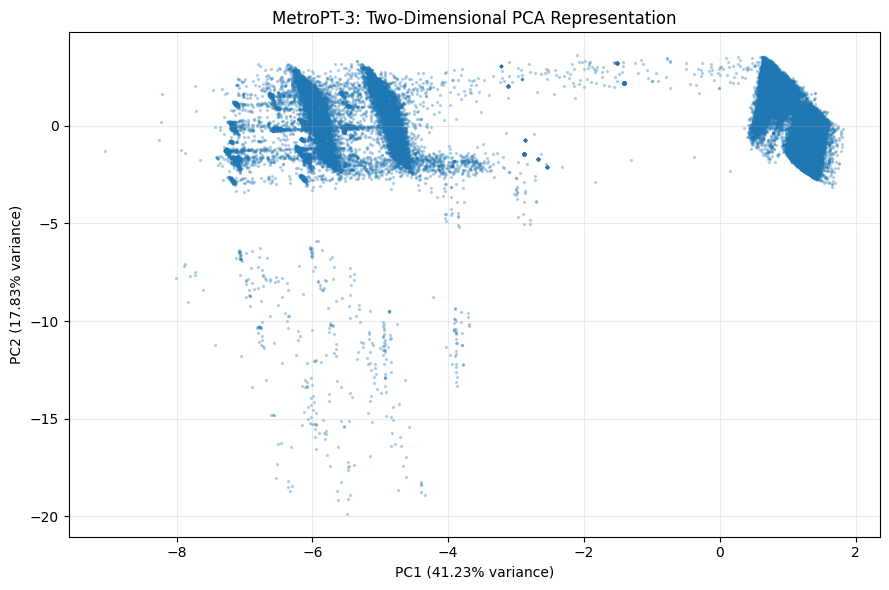

In [ ]:

# ============================================================
# PART A — CELL 3: PRINCIPAL COMPONENT ANALYSIS (PCA)
# ============================================================

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Apply PCA with two components
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

# Explained variance
explained_variance = pca.explained_variance_ratio_

print("=" * 60)
print("PART A — PCA RESULTS")
print("=" * 60)

print(f"\nOriginal dimensions: {X_scaled.shape[1]}")
print(f"Reduced dimensions: {X_pca.shape[1]}")

print(f"\nPC1 explained variance: {explained_variance[0]:.4f}")
print(f"PC2 explained variance: {explained_variance[1]:.4f}")
print(f"Total explained variance: {explained_variance.sum():.4f}")

# Visualise the 2D PCA representation
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    s=2,
    alpha=0.25,
    rasterized=True
)

plt.xlabel(f"PC1 ({explained_variance[0]*100:.2f}% variance)")
plt.ylabel(f"PC2 ({explained_variance[1]*100:.2f}% variance)")
plt.title("MetroPT-3: Two-Dimensional PCA Representation")

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


PART A — PCA LOADING ANALYSIS


,PC1,PC2
TP2,-0.3864,0.0097
TP3,0.0195,0.5892
H1,0.3851,0.1179
DV_pressure,-0.2055,-0.0513
Reservoirs,0.0200,0.5892
Oil_temperature,-0.1366,0.3502
Motor_current,-0.3006,0.2996
COMP,0.3946,0.0436
DV_eletric,-0.3889,-0.0306
Towers,0.2863,0.0298



Top 5 contributors to PC1:


,PC1
COMP,0.3946
MPG,0.3932
DV_eletric,-0.3889
TP2,-0.3864
H1,0.3851



Top 5 contributors to PC2:


,PC2
Reservoirs,0.5892
TP3,0.5892
Oil_temperature,0.3502
Motor_current,0.2996
LPS,-0.2507


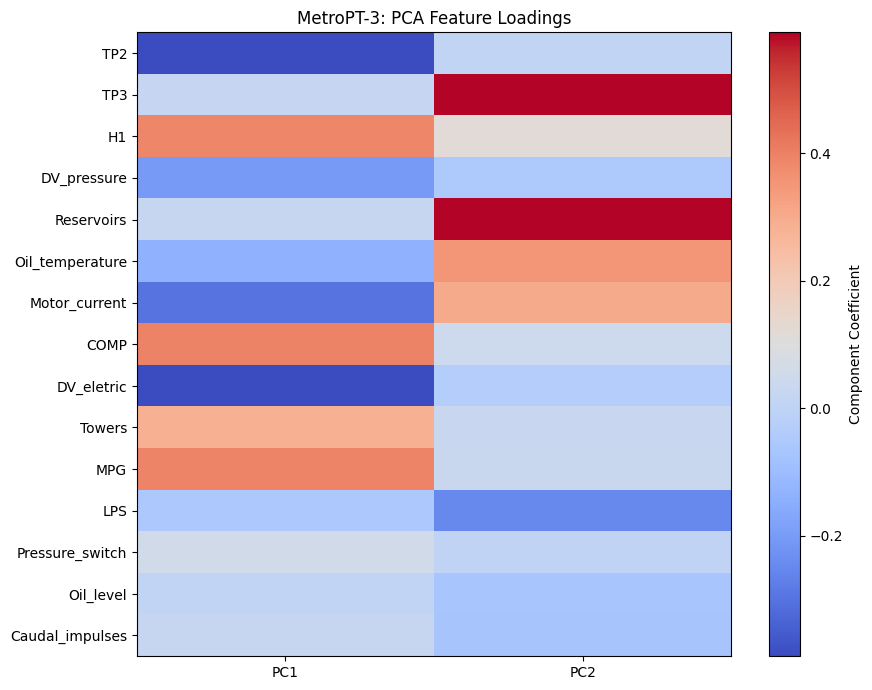

In [ ]:

# ============================================================
# PART A — CELL 3A: PCA LOADING ANALYSIS
# ============================================================

# Extract PCA component coefficients
pca_loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=["PC1", "PC2"]
)

print("=" * 60)
print("PART A — PCA LOADING ANALYSIS")
print("=" * 60)

display(pca_loadings.round(4))

# Identify top 5 contributing features
for pc in ["PC1", "PC2"]:
    print(f"\nTop 5 contributors to {pc}:")

    top_features = (
        pca_loadings[pc]
        .abs()
        .sort_values(ascending=False)
        .head(5)
    )

    display(
        pca_loadings.loc[top_features.index, [pc]].round(4)
    )

# Visualise PCA coefficients
plt.figure(figsize=(9, 7))

plt.imshow(
    pca_loadings.values,
    cmap="coolwarm",
    aspect="auto"
)

plt.colorbar(label="Component Coefficient")
plt.xticks([0, 1], ["PC1", "PC2"])
plt.yticks(range(len(X.columns)), X.columns)

plt.title("MetroPT-3: PCA Feature Loadings")
plt.tight_layout()
plt.show()


**Outcome of Requirement 1***

### Principal Component Analysis (PCA)

PCA successfully reduced the 15-dimensional MetroPT-3 sensor dataset to two principal components, preserving 59.06% of the total variance. The two-dimensional projection reveals several distinct clusters and dispersed observations, suggesting different underlying operating patterns. However, without labelled fault periods, these clusters cannot yet be conclusively associated with normal or faulty operation.

###PCA LOADING ANALYSIS

PC1 is primarily influenced by operational indicators (COMP, MPG and DV_eletric) alongside TP2 and H1, suggesting that it captures compressor operating-state variation. PC2 is dominated by Reservoirs and TP3 (both 0.5892), indicating a stronger association with pressure-related measurements. These findings demonstrate that binary and continuous features contribute differently to the learned PCA representation.

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 1.0258 - val_loss: 0.8609
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6563 - val_loss: 0.7035
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4768 - val_loss: 0.5977
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.4078 - val_loss: 0.5573
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3929 - val_loss: 0.5450
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3903 - val_loss: 0.5413
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3895 - val_loss: 0.5400
Epoch 8/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3892 - val_loss: 0.5393
Epoch 9/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3890 - val_loss: 0.5384
Epoch 10/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3888 - val_loss: 0.5373
Epoch 11/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3887 - val_loss: 0.5363
Epoch 12/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

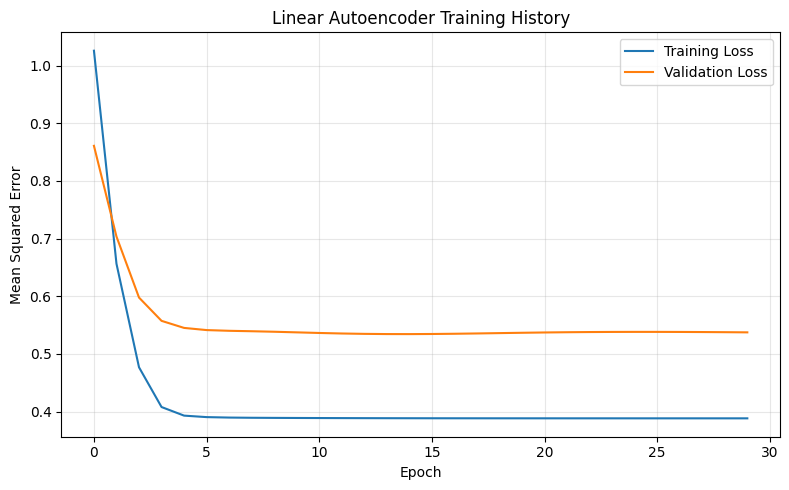

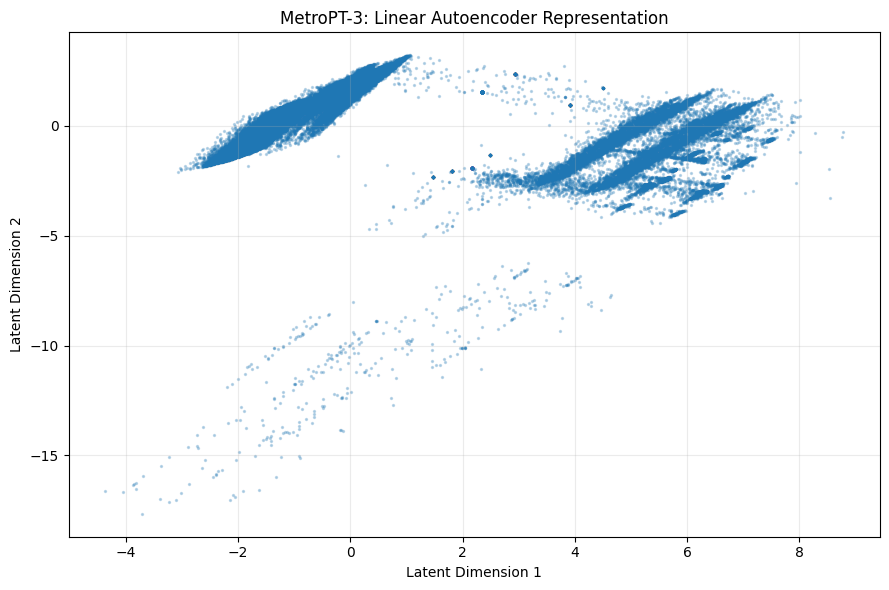

In [ ]:

# ============================================================
# PART A — CELL 4: LINEAR AUTOENCODER
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, Model

tf.keras.utils.set_random_seed(42)

# Linear autoencoder: 15 -> 2 -> 15
input_dim = X_scaled.shape[1]

inputs = layers.Input(shape=(input_dim,))

latent = layers.Dense(
    2,
    activation="linear",
    name="latent_representation"
)(inputs)

outputs = layers.Dense(
    input_dim,
    activation="linear",
    name="reconstruction"
)(latent)

autoencoder = Model(inputs, outputs)
encoder = Model(inputs, latent)

autoencoder.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

# Train the model
history = autoencoder.fit(
    X_scaled,
    X_scaled,
    epochs=30,
    batch_size=256,
    validation_split=0.2,
    shuffle=True,
    verbose=1
)

# Extract learned 2D representations
X_ae = encoder.predict(
    X_scaled,
    batch_size=1024,
    verbose=0
)

print("=" * 60)
print("LINEAR AUTOENCODER RESULTS")
print("=" * 60)

print(f"Input dimensions: {input_dim}")
print(f"Latent dimensions: {X_ae.shape[1]}")
print(f"Final training loss: {history.history['loss'][-1]:.6f}")
print(f"Final validation loss: {history.history['val_loss'][-1]:.6f}")

# Plot training history
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Linear Autoencoder Training History")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Visualise the learned 2D representation
plt.figure(figsize=(9, 6))
plt.scatter(
    X_ae[:, 0],
    X_ae[:, 1],
    s=2,
    alpha=0.25,
    rasterized=True
)
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("MetroPT-3: Linear Autoencoder Representation")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


The linear autoencoder reduced the 15 input features to a two-dimensional latent representation, achieving a final training MSE of 0.3882 and validation MSE of 0.5373. The latent projection reveals distinct clusters and dispersed observations, while the higher validation loss suggests differences in reconstruction performance between training and validation data.

In [ ]:

# ============================================================
# PART A — CELL 4A: PCA VS AUTOENCODER SUBSPACE SIMILARITY
# ============================================================

import numpy as np
from scipy.linalg import subspace_angles

# PCA basis in the original 15-dimensional feature space
pca_basis = pca.components_.T

# Linear autoencoder encoder weight matrix
ae_weights = encoder.get_layer(
    "latent_representation"
).get_weights()[0]

# Compare the two learned 2D subspaces
angles = subspace_angles(pca_basis, ae_weights)

angles_deg = np.degrees(angles)
similarity = np.cos(angles) ** 2

print("=" * 60)
print("PCA VS LINEAR AUTOENCODER SUBSPACE COMPARISON")
print("=" * 60)

print("\nPrincipal angles (degrees):")
print(np.round(angles_deg, 4))

print("\nSquared cosine similarities:")
print(np.round(similarity, 4))

print(f"\nMean subspace similarity: {similarity.mean():.4f}")


PCA VS LINEAR AUTOENCODER SUBSPACE COMPARISON

Principal angles (degrees):
[28.4107 17.3505]

Squared cosine similarities:
[0.7736 0.9111]

Mean subspace similarity: 0.8423


### PCA–Autoencoder Subspace Comparison

The PCA and linear autoencoder representations exhibit substantial subspace alignment, with principal angles of 28.41° and 17.35° and a mean squared-cosine similarity of 0.8423. This indicates that both methods capture largely overlapping linear structure, although their learned subspaces are not identical.

###Latent Dimension Sensitivity Analysis

This tests latent dimensions 2, 3 and 5, by keeping the architecture, learning rate and training settings consistent.

LATENT DIMENSION SENSITIVITY ANALYSIS


,Latent Dimensions,Training MSE,Validation MSE
0,2,0.388189,0.537330
1,3,0.283917,0.493528
2,5,0.150812,0.424266


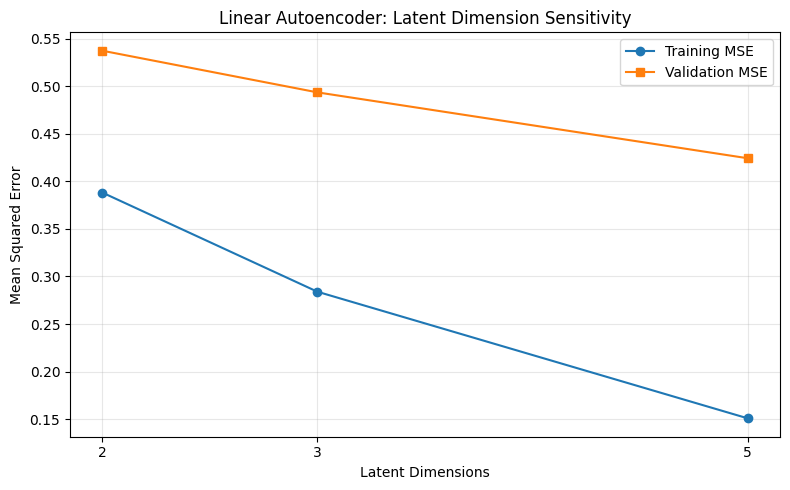

In [ ]:

# ============================================================
# PART A — CELL 4B: LATENT DIMENSION SENSITIVITY ANALYSIS
# ============================================================

from sklearn.metrics import mean_squared_error

latent_dimensions = [2, 3, 5]
results = []

for dim in latent_dimensions:

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    # Build linear autoencoder
    inputs = layers.Input(shape=(input_dim,))

    latent = layers.Dense(
        dim,
        activation="linear"
    )(inputs)

    outputs = layers.Dense(
        input_dim,
        activation="linear"
    )(latent)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    # Train with same configuration as original
    hist = model.fit(
        X_scaled,
        X_scaled,
        epochs=30,
        batch_size=256,
        validation_split=0.2,
        shuffle=True,
        verbose=0
    )

    results.append({
        "Latent Dimensions": dim,
        "Training MSE": hist.history["loss"][-1],
        "Validation MSE": hist.history["val_loss"][-1]
    })

# Display results
latent_results = pd.DataFrame(results)

print("=" * 60)
print("LATENT DIMENSION SENSITIVITY ANALYSIS")
print("=" * 60)

display(latent_results.round(6))

# Visual comparison
plt.figure(figsize=(8, 5))

plt.plot(
    latent_results["Latent Dimensions"],
    latent_results["Training MSE"],
    marker="o",
    label="Training MSE"
)

plt.plot(
    latent_results["Latent Dimensions"],
    latent_results["Validation MSE"],
    marker="s",
    label="Validation MSE"
)

plt.xlabel("Latent Dimensions")
plt.ylabel("Mean Squared Error")
plt.title("Linear Autoencoder: Latent Dimension Sensitivity")
plt.xticks(latent_dimensions)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Latent Dimension Sensitivity Analysis

Increasing latent dimensions from 2 to 5 reduced training MSE from 0.3882 to 0.1508 and validation MSE from 0.5373 to 0.4243. This demonstrates improved reconstruction with greater latent capacity, although the two-dimensional representation remains preferable for direct visualisation and stronger compression.

PART A — PCA VS LINEAR AUTOENCODER
PCA reconstruction MSE: 0.409382
Autoencoder reconstruction MSE: 0.417886


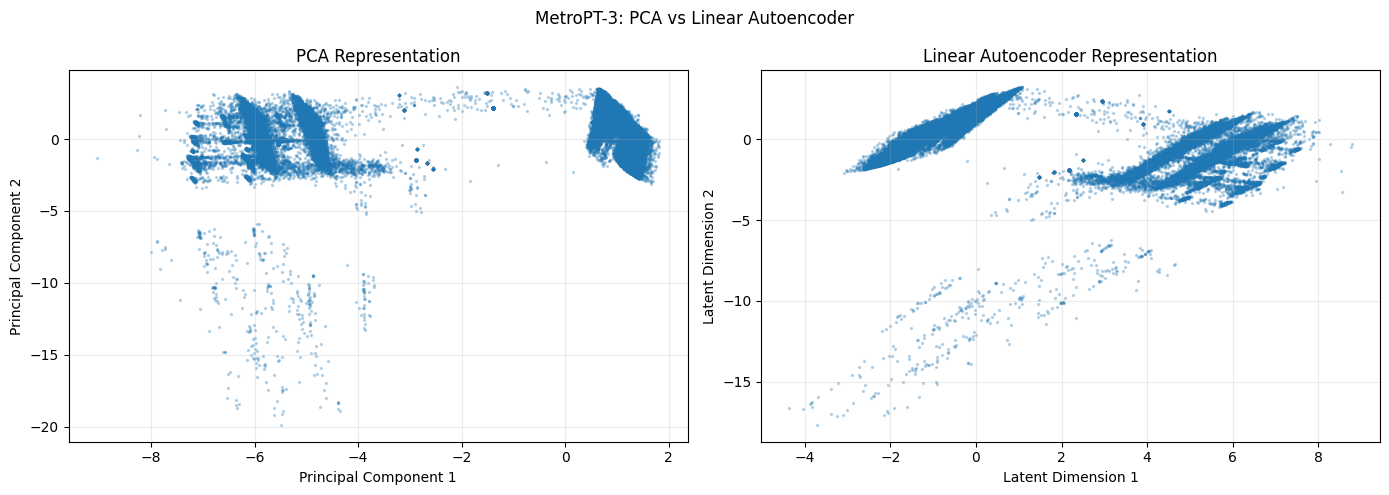

In [ ]:

# ============================================================
# PART A — CELL 5: PCA VS LINEAR AUTOENCODER
# ============================================================

from sklearn.metrics import mean_squared_error

# Reconstruct data using PCA
X_pca_reconstructed = pca.inverse_transform(X_pca)

# Reconstruct data using linear autoencoder
X_ae_reconstructed = autoencoder.predict(
    X_scaled,
    batch_size=1024,
    verbose=0
)

# Calculate reconstruction errors
pca_mse = mean_squared_error(
    X_scaled,
    X_pca_reconstructed
)

ae_mse = mean_squared_error(
    X_scaled,
    X_ae_reconstructed
)

print("=" * 60)
print("PART A — PCA VS LINEAR AUTOENCODER")
print("=" * 60)

print(f"PCA reconstruction MSE: {pca_mse:.6f}")
print(f"Autoencoder reconstruction MSE: {ae_mse:.6f}")

# Side-by-side visual comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    s=2,
    alpha=0.25,
    rasterized=True
)
axes[0].set_title("PCA Representation")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

axes[1].scatter(
    X_ae[:, 0],
    X_ae[:, 1],
    s=2,
    alpha=0.25,
    rasterized=True
)
axes[1].set_title("Linear Autoencoder Representation")
axes[1].set_xlabel("Latent Dimension 1")
axes[1].set_ylabel("Latent Dimension 2")

for ax in axes:
    ax.grid(alpha=0.25)

plt.suptitle("MetroPT-3: PCA vs Linear Autoencoder")
plt.tight_layout()
plt.show()


**Requirement 2 — Linear Autoencoder and PCA Comparison**

Both PCA and the linear autoencoder successfully reduced the MetroPT-3 dataset from 15 dimensions to two, revealing broadly similar operating patterns. PCA achieved a lower reconstruction MSE (0.409382) than the linear autoencoder (0.417886), demonstrating slightly better reconstruction performance. This is consistent with PCA's optimality for linear dimensionality reduction under squared reconstruction error.

Part A results will be strengthened by checking whether the clusters in our existing PCA and linear-autoencoder plots correspond to documented MetroPT-3 failure periods.

We won't train another model or introduce an optional method. We'll use the representations we've already calculated (X_pca and X_ae) and relate them to the original timestamps.

This matters because a visually isolated cluster does not necessarily represent a fault; it could simply reflect a different operating state

PART A — DOCUMENTED FAILURE PERIOD ANALYSIS
Total observations: 100,000
Within documented failure periods: 2,018
Outside documented failure periods: 97,982
Failure-period proportion: 2.02%


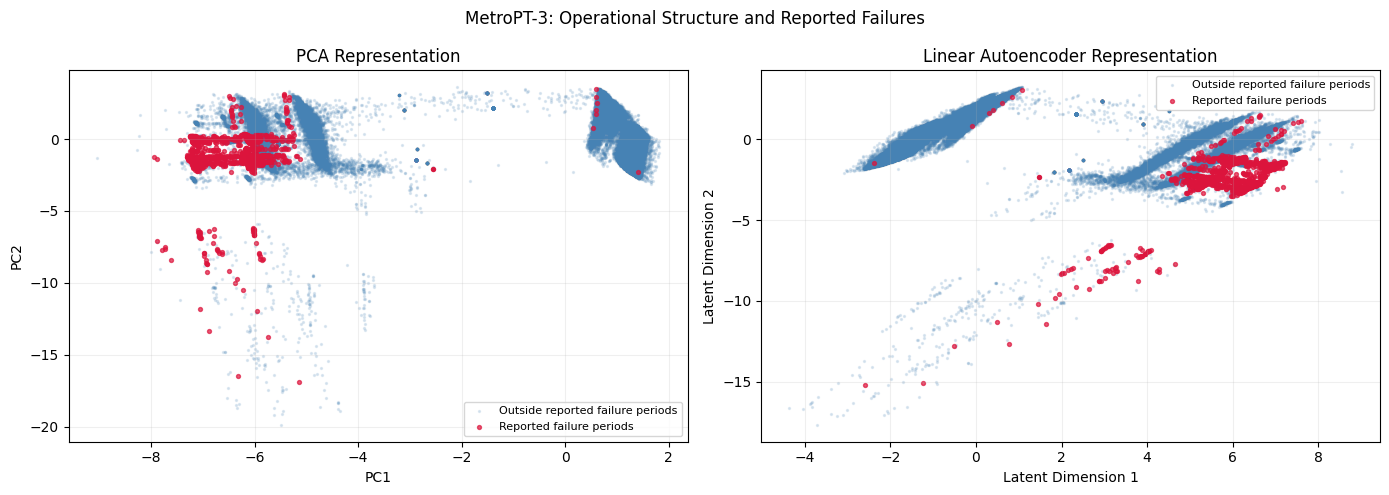

In [ ]:

# ============================================================
# PART A — CELL 6: OPERATIONAL STRUCTURE AND FAILURE PERIODS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Official MetroPT-3 reported failure periods
failure_periods = [
    ("2020-04-18 00:00", "2020-04-18 23:59"),
    ("2020-05-29 23:30", "2020-05-30 06:00"),
    ("2020-06-05 10:00", "2020-06-07 14:30"),
    ("2020-07-15 14:30", "2020-07-15 19:00")
]

# Use timestamps from the SAME sampled observations
timestamps = pd.to_datetime(df_sample["timestamp"])

failure_mask = np.zeros(len(df_sample), dtype=bool)

for start, end in failure_periods:
    failure_mask |= (
        (timestamps >= pd.Timestamp(start)) &
        (timestamps <= pd.Timestamp(end))
    ).to_numpy()

normal_mask = ~failure_mask

print("=" * 60)
print("PART A — DOCUMENTED FAILURE PERIOD ANALYSIS")
print("=" * 60)

print(f"Total observations: {len(df_sample):,}")
print(f"Within documented failure periods: {failure_mask.sum():,}")
print(f"Outside documented failure periods: {normal_mask.sum():,}")
print(f"Failure-period proportion: {failure_mask.mean()*100:.2f}%")

# Plot both existing representations with failure-period overlays
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

representations = [
    (X_pca, "PCA Representation", "PC1", "PC2"),
    (X_ae, "Linear Autoencoder Representation",
     "Latent Dimension 1", "Latent Dimension 2")
]

for ax, (coords, title, xlabel, ylabel) in zip(
    axes, representations
):
    ax.scatter(
        coords[normal_mask, 0],
        coords[normal_mask, 1],
        s=2,
        alpha=0.15,
        color="steelblue",
        label="Outside reported failure periods",
        rasterized=True
    )

    ax.scatter(
        coords[failure_mask, 0],
        coords[failure_mask, 1],
        s=8,
        alpha=0.7,
        color="crimson",
        label="Reported failure periods",
        rasterized=True
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

plt.suptitle("MetroPT-3: Operational Structure and Reported Failures")
plt.tight_layout()
plt.show()


**Interpretation of Operational Structure and Reported Failures**

Of the 100,000 sampled observations, 2,018 (2.02%) occurred during documented failure periods. Both PCA and the linear autoencoder revealed concentrations of failure-period observations within particular regions of their two-dimensional representations, alongside several dispersed observations. However, substantial overlap with observations outside reported failure periods indicates that neither method provides a clear distinction between operational states and documented failures.

### Overall Results and Interpretation — Part A

Part A investigated representation learning using 100,000 MetroPT-3 observations containing 15 standardised sensor and operational features. PCA reduced the data to two dimensions while retaining **59.06% of the total variance**. The linear autoencoder achieved a final training MSE of **0.3882** and validation MSE of **0.5373**.

Both methods revealed distinct operational structures, although their latent representations differed in orientation and scaling. PCA achieved a slightly lower reconstruction MSE (**0.4094**) than the linear autoencoder (**0.4179**), demonstrating a modest reconstruction advantage consistent with PCA's theoretical properties.

Analysis of documented failure periods identified **2,018 observations (2.02%)** within reported failure intervals. Both representations showed concentrations of these observations in particular regions, but considerable overlap with observations outside the reported failure periods prevented clear separation. This suggests that the methods capture underlying operational variability without independently establishing reliable fault identification.

**Overall, PCA and the linear autoencoder provided useful low-dimensional representations of the MetroPT-3 data, with PCA demonstrating slightly better reconstruction performance.** Their visualisations revealed meaningful operating patterns, while highlighting the limitations of unsupervised dimensionality reduction for distinguishing documented failures from other operating conditions.

* Part B - Sequence or Transfer Learning (complete this OR Part C; if completing this Part,
choose ONE track)
Track 1 — Transfer Learning (Buses and road vehicles):

• Fine-tune an ImageNet-pretrained CNN on a vehicle/bus damage or defect-detection image dataset.

• Compare its performance against training a CNN from scratch on the same data, and discuss the benefits and drawbacks you observed.

Track 2 — Recurrent Neural Networks (Aircraft):
• Build and train an RNN/LSTM on an aircraft engine time-series dataset to predict an upcoming failure event or estimate remaining useful life.
• Evaluate its predictive performance and discuss how well it captures the temporal pattern in the data.
State clearly in your report which track you chose and why.

* NASA C-MAPSS was selected for Part B because its sequential engine degradation data support remaining-useful-life prediction using recurrent neural networks. Together, the datasets enable complementary investigations of representation learning and temporal predictive modelling within transportation fleet maintenance.

In [ ]:

# ============================================================
# AMLNN ASSIGNMENT 2
# PART B — CELL 1: NASA C-MAPSS DATASET INSPECTION
# ============================================================

import os
import numpy as np
import pandas as pd

# Google Drive dataset directory
DATA_DIR = "/content/drive/MyDrive/AMLNN_AS2"

train_path = os.path.join(DATA_DIR, "train_FD001.txt")
test_path = os.path.join(DATA_DIR, "test_FD001.txt")
rul_path = os.path.join(DATA_DIR, "RUL_FD001.txt")

# Verify files exist
for path in [train_path, test_path, rul_path]:
    assert os.path.exists(path), f"File not found: {path}"

# NASA C-MAPSS column names
columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# Load whitespace-separated data
train_df = pd.read_csv(
    train_path,
    sep=r"\s+",
    header=None,
    names=columns
)

test_df = pd.read_csv(
    test_path,
    sep=r"\s+",
    header=None,
    names=columns
)

rul_df = pd.read_csv(
    rul_path,
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

print("=" * 65)
print("PART B — NASA C-MAPSS FD001 DATASET INSPECTION")
print("=" * 65)

print("\nDATASET DIMENSIONS")
print(f"Training data: {train_df.shape}")
print(f"Testing data: {test_df.shape}")
print(f"RUL labels: {rul_df.shape}")

print("\nNUMBER OF ENGINES")
print(f"Training engines: {train_df['engine_id'].nunique()}")
print(f"Testing engines: {test_df['engine_id'].nunique()}")

print("\nTRAINING DATA — FIRST FIVE ROWS")
display(train_df.head())

print("\nTESTING DATA — FIRST FIVE ROWS")
display(test_df.head())

print("\nRUL LABELS — FIRST FIVE ROWS")
display(rul_df.head())

print("\nMISSING VALUES")
print(f"Training: {train_df.isnull().sum().sum()}")
print(f"Testing: {test_df.isnull().sum().sum()}")
print(f"RUL labels: {rul_df.isnull().sum().sum()}")

print("\nENGINE OPERATING CYCLES")
print(
    train_df.groupby("engine_id")["cycle"]
    .max()
    .describe()
)

print("\nSENSOR COLUMNS")
print([col for col in train_df.columns if col.startswith("sensor_")])


PART B — NASA C-MAPSS FD001 DATASET INSPECTION

DATASET DIMENSIONS
Training data: (20631, 26)
Testing data: (13096, 26)
RUL labels: (100, 1)

NUMBER OF ENGINES
Training engines: 100
Testing engines: 100

TRAINING DATA — FIRST FIVE ROWS


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044



TESTING DATA — FIRST FIVE ROWS


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130



RUL LABELS — FIRST FIVE ROWS


,RUL
0,112
1,98
2,69
3,82
4,91



MISSING VALUES
Training: 0
Testing: 0
RUL labels: 0

ENGINE OPERATING CYCLES
count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64

SENSOR COLUMNS
['sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']


In [ ]:

# ============================================================
# PART B — CELL 2: RUL TARGETS AND PREPROCESSING
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Construct training RUL targets
max_cycles = train_df.groupby("engine_id")["cycle"].max()

train_df["RUL"] = (
    train_df["engine_id"].map(max_cycles)
    - train_df["cycle"]
)

# 2. Select sensor and operational features
candidate_features = (
    [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# Remove features that are constant in training data
feature_columns_b = [
    col for col in candidate_features
    if train_df[col].nunique() > 1
]

removed_features = [
    col for col in candidate_features
    if col not in feature_columns_b
]

# 3. Split by engine ID to prevent leakage
engine_ids = train_df["engine_id"].unique()

train_ids, val_ids = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42
)

train_part = train_df[
    train_df["engine_id"].isin(train_ids)
].copy()

val_part = train_df[
    train_df["engine_id"].isin(val_ids)
].copy()

test_part = test_df.copy()

# 4. Fit scaler ONLY on training engines
scaler_b = StandardScaler()

train_part[feature_columns_b] = scaler_b.fit_transform(
    train_part[feature_columns_b]
)

val_part[feature_columns_b] = scaler_b.transform(
    val_part[feature_columns_b]
)

test_part[feature_columns_b] = scaler_b.transform(
    test_part[feature_columns_b]
)

# 5. Report results
print("=" * 65)
print("PART B — RUL TARGETS AND PREPROCESSING")
print("=" * 65)

print("\nTRAINING RUL SUMMARY")
print(train_df["RUL"].describe())

print("\nENGINE-WISE SPLIT")
print(f"Training engines: {len(train_ids)}")
print(f"Validation engines: {len(val_ids)}")
print(f"Testing engines: {test_part['engine_id'].nunique()}")

print("\nFEATURE SELECTION")
print(f"Original candidate features: {len(candidate_features)}")
print(f"Retained features: {len(feature_columns_b)}")
print(f"Removed constant features: {removed_features}")

print("\nPREPROCESSED DATA SHAPES")
print(f"Training: {train_part.shape}")
print(f"Validation: {val_part.shape}")
print(f"Testing: {test_part.shape}")

print("\nFIRST FIVE TRAINING RUL VALUES")
display(
    train_df[["engine_id", "cycle", "RUL"]].head()
)


PART B — RUL TARGETS AND PREPROCESSING

TRAINING RUL SUMMARY
count    20631.000000
mean       107.807862
std         68.880990
min          0.000000
25%         51.000000
50%        103.000000
75%        155.000000
max        361.000000
Name: RUL, dtype: float64

ENGINE-WISE SPLIT
Training engines: 80
Validation engines: 20
Testing engines: 100

FEATURE SELECTION
Original candidate features: 24
Retained features: 17
Removed constant features: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

PREPROCESSED DATA SHAPES
Training: (16561, 27)
Validation: (4070, 27)
Testing: (13096, 26)

FIRST FIVE TRAINING RUL VALUES


,engine_id,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


Remaining useful life (RUL) targets were calculated from each training engine's final operating cycle, producing values between 0 and 361 cycles. An engine-wise split allocated 80 engines for training and 20 for validation, preventing overlap between the two groups. Seven constant features were removed, and the remaining 17 features were standardised using training-only statistics to support LSTM learning without preprocessing leakage.

In [ ]:

# ============================================================
# PART B — CELL 3: LSTM SEQUENCE CONSTRUCTION
# ============================================================

import numpy as np

SEQUENCE_LENGTH = 30

def create_training_sequences(data, features, seq_length):
    X_sequences = []
    y_targets = []

    for engine_id, group in data.groupby("engine_id"):
        group = group.sort_values("cycle")

        sensor_values = group[features].to_numpy(
            dtype=np.float32
        )
        rul_values = group["RUL"].to_numpy(
            dtype=np.float32
        )

        for i in range(len(group) - seq_length + 1):
            X_sequences.append(
                sensor_values[i:i + seq_length]
            )
            y_targets.append(
                rul_values[i + seq_length - 1]
            )

    return (
        np.asarray(X_sequences, dtype=np.float32),
        np.asarray(y_targets, dtype=np.float32)
    )


def create_test_sequences(data, features, seq_length):
    X_sequences = []

    for engine_id, group in data.groupby("engine_id"):
        group = group.sort_values("cycle")

        sensor_values = group[features].to_numpy(
            dtype=np.float32
        )

        # Use final available window for each test engine
        sequence = sensor_values[-seq_length:]

        # Left-pad if an engine has fewer than 30 cycles
        if len(sequence) < seq_length:
            padding = np.repeat(
                sequence[:1],
                seq_length - len(sequence),
                axis=0
            )
            sequence = np.vstack([padding, sequence])

        X_sequences.append(sequence)

    return np.asarray(X_sequences, dtype=np.float32)


# Create training and validation sequences
X_train_seq, y_train_seq = create_training_sequences(
    train_part,
    feature_columns_b,
    SEQUENCE_LENGTH
)

X_val_seq, y_val_seq = create_training_sequences(
    val_part,
    feature_columns_b,
    SEQUENCE_LENGTH
)

# Create test sequences
X_test_seq = create_test_sequences(
    test_part,
    feature_columns_b,
    SEQUENCE_LENGTH
)

# Test RUL labels
y_test = rul_df["RUL"].to_numpy(dtype=np.float32)

# Verify alignment
assert len(X_test_seq) == len(y_test)

print("=" * 65)
print("PART B — LSTM SEQUENCE CONSTRUCTION")
print("=" * 65)

print(f"\nSequence length: {SEQUENCE_LENGTH} cycles")
print(f"Features per cycle: {len(feature_columns_b)}")

print("\nTRAINING SEQUENCES")
print(f"X_train: {X_train_seq.shape}")
print(f"y_train: {y_train_seq.shape}")

print("\nVALIDATION SEQUENCES")
print(f"X_val: {X_val_seq.shape}")
print(f"y_val: {y_val_seq.shape}")

print("\nTEST SEQUENCES")
print(f"X_test: {X_test_seq.shape}")
print(f"y_test: {y_test.shape}")

print("\nTARGET RANGES")
print(f"Training RUL: {y_train_seq.min():.0f} to {y_train_seq.max():.0f}")
print(f"Validation RUL: {y_val_seq.min():.0f} to {y_val_seq.max():.0f}")
print(f"Testing RUL: {y_test.min():.0f} to {y_test.max():.0f}")

print("\nSequence construction completed successfully.")


PART B — LSTM SEQUENCE CONSTRUCTION

Sequence length: 30 cycles
Features per cycle: 17

TRAINING SEQUENCES
X_train: (14241, 30, 17)
y_train: (14241,)

VALIDATION SEQUENCES
X_val: (3490, 30, 17)
y_val: (3490,)

TEST SEQUENCES
X_test: (100, 30, 17)
y_test: (100,)

TARGET RANGES
Training RUL: 0 to 332
Validation RUL: 0 to 239
Testing RUL: 7 to 145

Sequence construction completed successfully.


### Sequence Length Justification

A 30-cycle sliding window was selected to capture recent temporal patterns in engine degradation while limiting computational complexity. This choice balances historical context against model efficiency and will be evaluated through sensitivity experiments using alternative window lengths.

### Methodological Interpretation

The preprocessed engine sensor measurements were organised into 30-cycle sequences containing 17 features per cycle. This produced 14,241 training sequences, 3,490 validation sequences, and 100 test sequences. Each training sequence was assigned the remaining useful life at its final cycle, enabling the LSTM to learn relationships between historical sensor measurements and engine degradation.

### LSTM Architecture and Hyperparameter Justification

An LSTM was selected for aircraft engine remaining useful life (RUL) prediction because engine degradation evolves over successive operational cycles, making the temporal ordering of sensor measurements relevant. Its gated memory mechanism enables information from earlier observations to influence subsequent predictions.

Alternative architectures were considered conceptually:

- **GRU:** Provides a computationally simpler recurrent architecture with fewer gates and typically fewer parameters. However, the LSTM's separate cell and hidden states offer a suitable mechanism for modelling temporal dependencies.
- **1D-CNN:** Efficiently extracts local temporal patterns through convolutional filters, whereas an LSTM maintains a recurrent representation across the observation window.
- **MLP:** Can process flattened sensor sequences but lacks an explicit recurrent mechanism for representing temporal state transitions.

A **30-cycle window** was selected as an initial compromise between retaining recent degradation history and limiting computational complexity. The baseline architecture used **64 LSTM units** to provide moderate representational capacity without adopting a larger recurrent network initially.

These choices were treated as baseline design assumptions rather than optimal configurations. Controlled sensitivity experiments subsequently evaluated 20-, 30- and 40-cycle windows and architectures containing 32, 64 and 128 LSTM units. The experiments demonstrated that model performance was sensitive to both parameters, with larger configurations achieving lower validation errors under the tested conditions. No direct GRU, CNN or MLP benchmarking was conducted; therefore, comparative superiority of the LSTM is not claimed.

PART B — LSTM MODEL ARCHITECTURE


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        20,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,057 (82.25 KB)

 Trainable params: 21,057 (82.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 11172.5947 - mae: 85.9826 - val_loss: 9000.0107 - val_mae: 76.4915
Epoch 2/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 9399.5342 - mae: 75.8926 - val_loss: 7855.2627 - val_mae: 69.4774
Epoch 3/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 8336.3848 - mae: 69.7041 - val_loss: 6932.1289 - val_mae: 63.7719
Epoch 4/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 7442.0020 - mae: 64.3523 - val_loss: 6142.5103 - val_mae: 58.7769
Epoch 5/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 6665.8442 - mae: 59.5224 - val_loss: 5456.4541 - val_mae: 54.3455
Epoch 6/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 5986.3247 - mae: 55.1962 - val_loss: 4853.9858 - val_mae: 50.1913
Epoch 7/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 5387.5430 - mae: 51.2301 - val_loss: 4326.9927 - val_mae: 46.5601
Epoch 8/40
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 4859.8970 - mae: 47.6725 - val_loss: 3863.0549 - val_ma

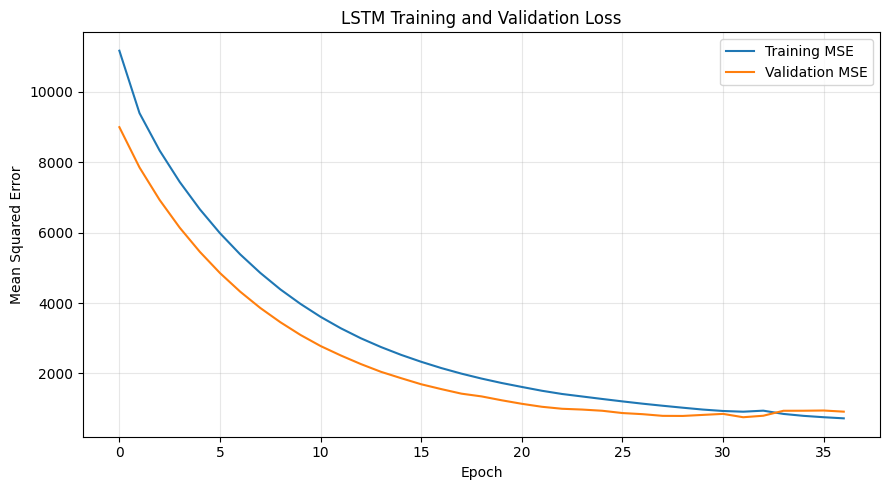

In [ ]:

# ============================================================
# PART B — CELL 4: BUILD AND TRAIN LSTM MODEL
# ============================================================

import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Build LSTM model
lstm_model = Sequential([
    Input(shape=(SEQUENCE_LENGTH, len(feature_columns_b))),
    LSTM(64),
    Dense(1)
])

# Compile model
lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

print("=" * 65)
print("PART B — LSTM MODEL ARCHITECTURE")
print("=" * 65)

lstm_model.summary()

# Stop training if validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train model
history_lstm = lstm_model.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=40,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)

print("\n" + "=" * 65)
print("PART B — LSTM TRAINING RESULTS")
print("=" * 65)

print(f"Epochs completed: {len(history_lstm.history['loss'])}")

print(
    f"Final training MSE: "
    f"{history_lstm.history['loss'][-1]:.4f}"
)

print(
    f"Final validation MSE: "
    f"{history_lstm.history['val_loss'][-1]:.4f}"
)

print(
    f"Best validation MSE: "
    f"{min(history_lstm.history['val_loss']):.4f}"
)

# Plot training and validation loss
plt.figure(figsize=(9, 5))

plt.plot(
    history_lstm.history["loss"],
    label="Training MSE"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


The LSTM completed 37 epochs, achieving a best validation MSE of 756.57 (RMSE ≈ 27.51 cycles). Training and validation losses decreased substantially, indicating successful optimisation. Late-stage validation fluctuations suggest diminishing generalisation improvements, supporting the use of early stopping and best-weight restoration.

###LSTM unit sensitivity

,LSTM Units,Best Validation MSE,Validation RMSE,Epochs
0,32,1150.318604,33.916347,40
1,64,756.574158,27.505893,37
2,128,557.380310,23.608903,34


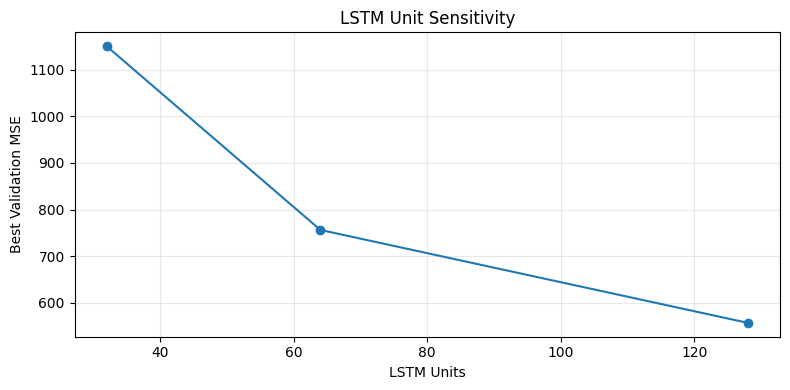

In [ ]:

# PART B — CELL 4A: LSTM UNIT SENSITIVITY

unit_results = []

for units in [32, 64, 128]:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = Sequential([
        Input(shape=(SEQUENCE_LENGTH, len(feature_columns_b))),
        LSTM(units),
        Dense(1)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    hist = model.fit(
        X_train_seq, y_train_seq,
        validation_data=(X_val_seq, y_val_seq),
        epochs=40,
        batch_size=128,
        callbacks=[stopping],
        verbose=0
    )

    best_mse = min(hist.history["val_loss"])

    unit_results.append({
        "LSTM Units": units,
        "Best Validation MSE": best_mse,
        "Validation RMSE": np.sqrt(best_mse),
        "Epochs": len(hist.history["loss"])
    })

unit_results_df = pd.DataFrame(unit_results)
display(unit_results_df)

plt.figure(figsize=(8, 4))
plt.plot(
    unit_results_df["LSTM Units"],
    unit_results_df["Best Validation MSE"],
    marker="o"
)
plt.xlabel("LSTM Units")
plt.ylabel("Best Validation MSE")
plt.title("LSTM Unit Sensitivity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### LSTM Unit Sensitivity Analysis

Increasing LSTM units from 32 to 128 progressively reduced validation MSE from 1150.32 to 557.38. The 128-unit configuration achieved the lowest validation RMSE (23.61 cycles), outperforming the original 64-unit model (27.51 cycles). These results suggest that greater model capacity improves RUL prediction within the tested configurations, although additional computational cost and generalisation uncertainty remain considerations.

### Learning Rate Sensitivity by keeping the original 64 units and 30-cycle window fixed.

,Learning Rate,Best Validation MSE,Validation RMSE,Epochs
0,0.0005,1168.614380,34.185002,40
1,0.0010,756.574158,27.505893,37
2,0.0020,699.293152,26.444152,30


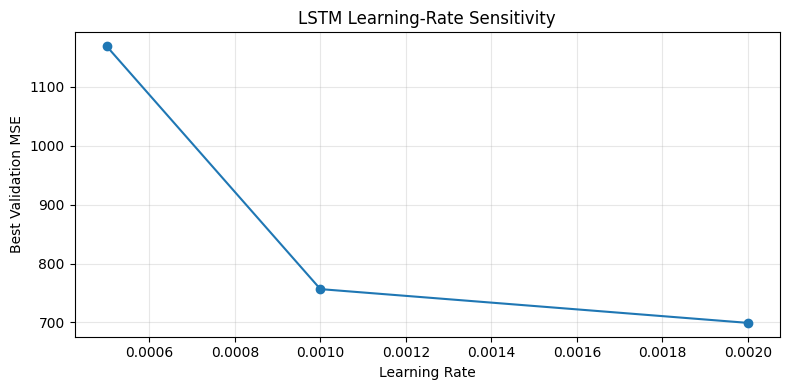

In [ ]:

# PART B — CELL 4B: LEARNING-RATE SENSITIVITY

lr_results = []

for lr in [0.0005, 0.001, 0.002]:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = Sequential([
        Input(shape=(SEQUENCE_LENGTH, len(feature_columns_b))),
        LSTM(64),
        Dense(1)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="mse",
        metrics=["mae"]
    )

    stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    hist = model.fit(
        X_train_seq, y_train_seq,
        validation_data=(X_val_seq, y_val_seq),
        epochs=40,
        batch_size=128,
        callbacks=[stopping],
        verbose=0
    )

    best_mse = min(hist.history["val_loss"])

    lr_results.append({
        "Learning Rate": lr,
        "Best Validation MSE": best_mse,
        "Validation RMSE": np.sqrt(best_mse),
        "Epochs": len(hist.history["loss"])
    })

lr_results_df = pd.DataFrame(lr_results)
display(lr_results_df)

plt.figure(figsize=(8, 4))
plt.plot(
    lr_results_df["Learning Rate"],
    lr_results_df["Best Validation MSE"],
    marker="o"
)
plt.xlabel("Learning Rate")
plt.ylabel("Best Validation MSE")
plt.title("LSTM Learning-Rate Sensitivity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Verify learning-rate sensitivity results
print("LEARNING-RATE CROSS-CHECK")
print("=" * 55)

for _, row in lr_results_df.iterrows():
    print(
        f"LR: {row['Learning Rate']:.4f} | "
        f"Epochs: {int(row['Epochs'])} | "
        f"Best Val MSE: {row['Best Validation MSE']:.4f} | "
        f"RMSE: {row['Validation RMSE']:.4f}"
    )

assert int(
    lr_results_df.loc[
        np.isclose(lr_results_df["Learning Rate"], 0.002),
        "Epochs"
    ].iloc[0]
) == 30

print("\nPASS: Learning rate 0.002 completed 30 epochs.")


LEARNING-RATE CROSS-CHECK
LR: 0.0005 | Epochs: 40 | Best Val MSE: 1168.6144 | RMSE: 34.1850
LR: 0.0010 | Epochs: 37 | Best Val MSE: 756.5742 | RMSE: 27.5059
LR: 0.0020 | Epochs: 30 | Best Val MSE: 699.2932 | RMSE: 26.4442

PASS: Learning rate 0.002 completed 30 epochs.


### Learning-Rate Sensitivity Analysis

Increasing the Adam learning rate from 0.0005 to 0.002 reduced the best validation MSE from 1168.61 to 699.29. The learning rate of 0.002 achieved the lowest observed validation RMSE (26.44 cycles), compared with 27.51 cycles for the baseline learning rate of 0.001. Training completed 30 epochs at 0.002, compared with 37 epochs at 0.001, indicating faster convergence under the tested configuration. These findings are based on validation performance and do not establish general superiority across other datasets or training conditions.

### WINDOW LENGTH SENSITIVITY : Testing 20, 30 and 40 cycles, keeping 64 LSTM units and a learning rate of 0.001 fixed.

,Window Length,Best Validation MSE,Validation RMSE,Epochs
0,20,1077.700073,32.828343,34
1,30,756.574158,27.505893,37
2,40,606.384888,24.624884,37


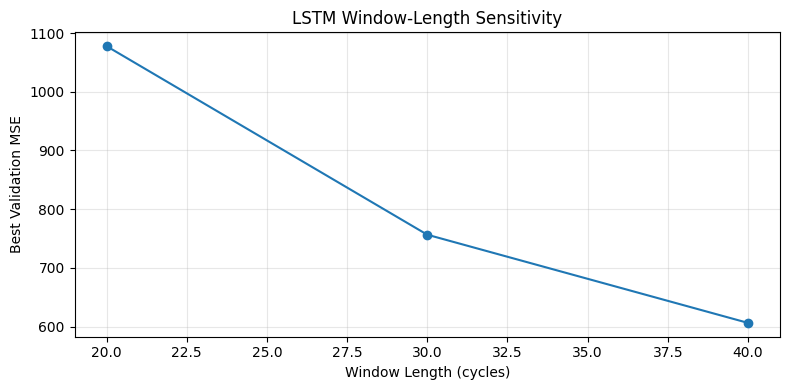

In [ ]:

# PART B — CELL 4C: WINDOW-LENGTH SENSITIVITY

window_results = []

for window in [20, 30, 40]:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    X_tr, y_tr = create_training_sequences(
        train_part, feature_columns_b, window
    )

    X_va, y_va = create_training_sequences(
        val_part, feature_columns_b, window
    )

    model = Sequential([
        Input(shape=(window, len(feature_columns_b))),
        LSTM(64),
        Dense(1)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    stopping = EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    hist = model.fit(
        X_tr, y_tr,
        validation_data=(X_va, y_va),
        epochs=40,
        batch_size=128,
        callbacks=[stopping],
        verbose=0
    )

    best_mse = min(hist.history["val_loss"])

    window_results.append({
        "Window Length": window,
        "Best Validation MSE": best_mse,
        "Validation RMSE": np.sqrt(best_mse),
        "Epochs": len(hist.history["loss"])
    })

window_results_df = pd.DataFrame(window_results)
display(window_results_df)

plt.figure(figsize=(8, 4))
plt.plot(
    window_results_df["Window Length"],
    window_results_df["Best Validation MSE"],
    marker="o"
)
plt.xlabel("Window Length (cycles)")
plt.ylabel("Best Validation MSE")
plt.title("LSTM Window-Length Sensitivity")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Window-Length Sensitivity Analysis

Increasing the sequence length from 20 to 40 cycles reduced validation MSE from 1077.70 to 606.38. The 40-cycle window achieved the lowest observed validation RMSE (24.62 cycles), suggesting that longer temporal histories provide useful information for engine RUL prediction. However, changing window length also changes the validation sequence population, limiting direct comparability.

PART B — LSTM TEST PERFORMANCE
Test MAE:  17.0698 cycles
Test MSE:  538.0271
Test RMSE: 23.1954 cycles
Test R²:   0.6884

FIRST 10 ENGINE PREDICTIONS


,Engine,Actual_RUL,Predicted_RUL
0,1,112.0,145.470001
1,2,98.0,140.880005
2,3,69.0,36.430000
3,4,82.0,76.029999
4,5,91.0,139.970001
5,6,93.0,105.739998
6,7,91.0,92.180000
7,8,95.0,142.940002
8,9,111.0,145.309998
9,10,96.0,83.120003


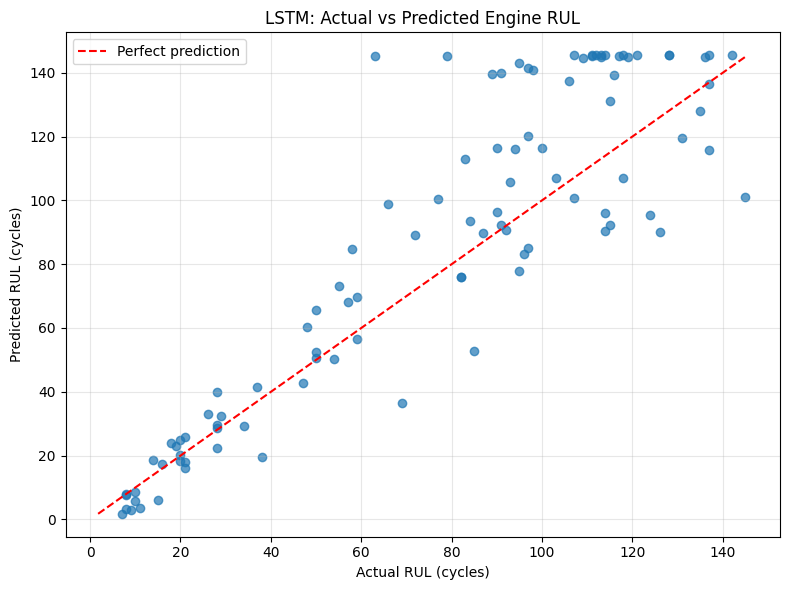

In [ ]:

# ============================================================
# PART B — CELL 5: LSTM TEST PERFORMANCE EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict RUL for the 100 unseen test engines
y_pred = lstm_model.predict(
    X_test_seq,
    verbose=0
).flatten()

# RUL cannot be negative
y_pred = np.maximum(y_pred, 0)

# Calculate regression metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("=" * 65)
print("PART B — LSTM TEST PERFORMANCE")
print("=" * 65)

print(f"Test MAE:  {mae:.4f} cycles")
print(f"Test MSE:  {mse:.4f}")
print(f"Test RMSE: {rmse:.4f} cycles")
print(f"Test R²:   {r2:.4f}")

# Actual vs predicted RUL
results_df = pd.DataFrame({
    "Engine": np.arange(1, len(y_test) + 1),
    "Actual_RUL": y_test,
    "Predicted_RUL": y_pred
})

print("\nFIRST 10 ENGINE PREDICTIONS")
display(results_df.head(10).round(2))

# Plot actual versus predicted RUL
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(
    limits,
    limits,
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("LSTM: Actual vs Predicted Engine RUL")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


INTERPRETATION:

Low RUL (0–30 cycles): Predictions generally follow the ideal diagonal, indicating reasonable performance near engine failure.



Intermediate RUL (40–100 cycles): Errors become more dispersed, with both overestimation and underestimation.



High RUL (100+ cycles): Several predictions cluster around 145 cycles, suggesting possible saturation in the model's predictions.

### LSTM Test Performance

The baseline LSTM achieved a test MAE of 17.07 cycles, RMSE of 23.20 cycles and R² of 0.6884 across 100 unseen engines. These results demonstrate useful predictive performance, although residual errors remain substantial for some engines, particularly at intermediate and higher RUL values.


Overall: The model captures the increasing relationship between actual and predicted RUL, but prediction accuracy varies across the operating lifetime.

### Part B — Track 2: LSTM-Based Aircraft Engine RUL Prediction

#### Dataset and Model Selection

NASA C-MAPSS FD001 was selected because it provides multivariate engine sensor measurements, run-to-failure trajectories and labelled remaining useful life (RUL) targets, making it suitable for supervised predictive maintenance. Track 2 was chosen to investigate temporal degradation patterns through RUL regression.

An LSTM was selected for its ability to model sequential dependencies through gated memory, unlike a conventional MLP, while offering a recurrent alternative to GRU and 1D-CNN architectures. The model processed 30-cycle sequences containing 17 standardised features, using an engine-wise training-validation split to prevent leakage and early stopping to limit overfitting. The initial 30-cycle window and 64-unit architecture were subsequently examined through controlled sensitivity experiments.

#### Results and Interpretation

The baseline LSTM achieved a test MAE of 17.07 cycles, RMSE of 23.20 cycles and R² of 0.6884. Actual-versus-predicted analysis showed relatively accurate predictions for engines approaching failure, while RUL was particularly overestimated in the 61–90 cycle range, indicating limitations in distinguishing intermediate degradation stages.

Overall, the LSTM demonstrated useful predictive capability, although accuracy varied across the engine lifecycle. These findings support the application of recurrent neural networks to sequential predictive-maintenance tasks while highlighting the importance of evaluating prediction errors before operational deployment.

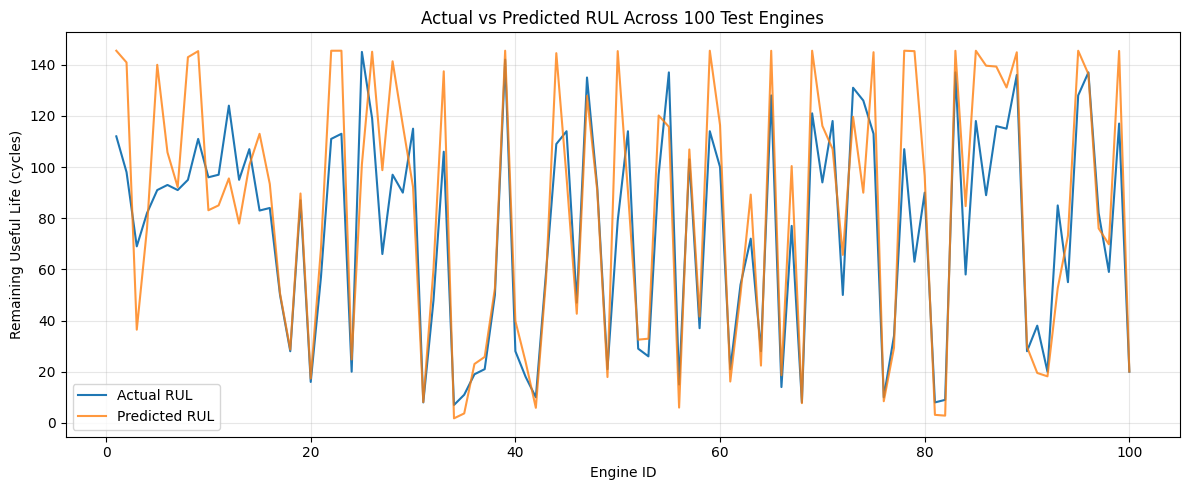

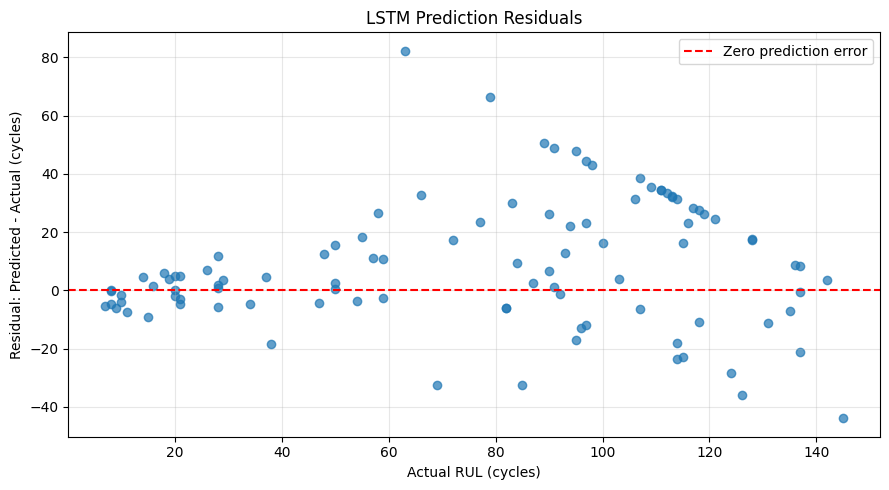

PART B — ERROR ANALYSIS BY RUL RANGE


,Engines,MAE,Mean_Residual
RUL_Range,,,
0-30,25,4.161000,-0.147000
31-60,14,9.749000,4.923000
61-90,15,28.291000,18.040001
Above 90,46,22.655001,10.755000


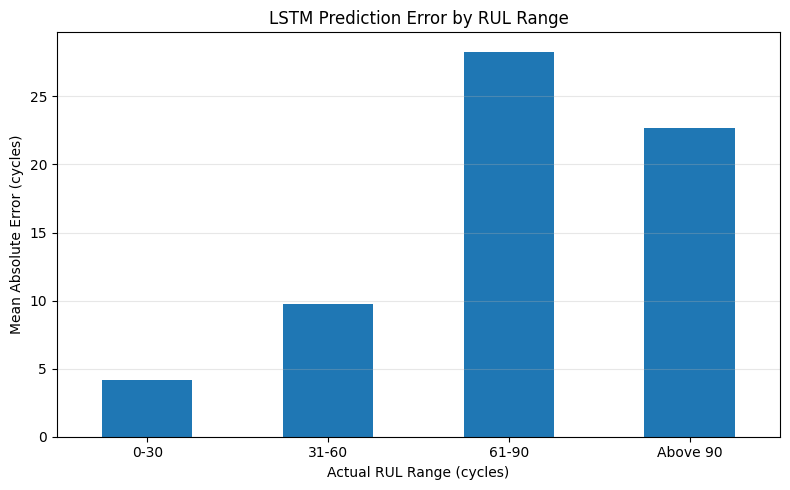


PREDICTION AGREEMENT
Predictions within ±10 cycles: 45.00%
Predictions within ±20 cycles: 64.00%
Mean prediction bias: 8.306 cycles


In [ ]:

# ============================================================
# PART B — CELL 6: PREDICTION AGREEMENT AND ERROR ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use existing test predictions from Cell 5
comparison_df = pd.DataFrame({
    "Engine": np.arange(1, len(y_test) + 1),
    "Actual_RUL": y_test,
    "Predicted_RUL": y_pred
})

comparison_df["Residual"] = (
    comparison_df["Predicted_RUL"]
    - comparison_df["Actual_RUL"]
)

comparison_df["Absolute_Error"] = (
    comparison_df["Residual"].abs()
)

# ------------------------------------------------------------
# FIGURE 1: ACTUAL VS PREDICTED RUL BY ENGINE
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    comparison_df["Engine"],
    comparison_df["Actual_RUL"],
    label="Actual RUL",
    linewidth=1.5
)

plt.plot(
    comparison_df["Engine"],
    comparison_df["Predicted_RUL"],
    label="Predicted RUL",
    linewidth=1.5,
    alpha=0.8
)

plt.xlabel("Engine ID")
plt.ylabel("Remaining Useful Life (cycles)")
plt.title("Actual vs Predicted RUL Across 100 Test Engines")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# FIGURE 2: RESIDUAL ERROR ANALYSIS
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.scatter(
    comparison_df["Actual_RUL"],
    comparison_df["Residual"],
    alpha=0.7
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
    label="Zero prediction error"
)

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Residual: Predicted - Actual (cycles)")
plt.title("LSTM Prediction Residuals")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# FIGURE 3: ERROR BY ENGINE LIFE STAGE
# ------------------------------------------------------------

comparison_df["RUL_Range"] = pd.cut(
    comparison_df["Actual_RUL"],
    bins=[-np.inf, 30, 60, 90, np.inf],
    labels=[
        "0-30",
        "31-60",
        "61-90",
        "Above 90"
    ]
)

error_summary = (
    comparison_df
    .groupby("RUL_Range", observed=True)
    .agg(
        Engines=("Engine", "count"),
        MAE=("Absolute_Error", "mean"),
        Mean_Residual=("Residual", "mean")
    )
)

print("=" * 65)
print("PART B — ERROR ANALYSIS BY RUL RANGE")
print("=" * 65)

display(error_summary.round(3))

error_summary["MAE"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Actual RUL Range (cycles)")
plt.ylabel("Mean Absolute Error (cycles)")
plt.title("LSTM Prediction Error by RUL Range")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# ADDITIONAL AGREEMENT STATISTICS
# ------------------------------------------------------------

within_10 = np.mean(
    comparison_df["Absolute_Error"] <= 10
) * 100

within_20 = np.mean(
    comparison_df["Absolute_Error"] <= 20
) * 100

mean_bias = comparison_df["Residual"].mean()

print("\nPREDICTION AGREEMENT")
print(f"Predictions within ±10 cycles: {within_10:.2f}%")
print(f"Predictions within ±20 cycles: {within_20:.2f}%")
print(f"Mean prediction bias: {mean_bias:.3f} cycles")


### Prediction Agreement and Residual Analysis

### Prediction Agreement and Residual Analysis

The LSTM achieved its lowest MAE of 4.16 cycles for engines with 0–30 cycles remaining, indicating stronger predictive agreement near failure. Error increased in the 61–90 cycle range (MAE = 28.29), accompanied by a positive mean residual of 18.04 cycles. Overall, 45% of predictions fell within ±10 cycles and 64% within ±20 cycles, with a mean positive bias of 8.31 cycles. These findings indicate an overall tendency to overestimate RUL, particularly during intermediate degradation stages, which could delay maintenance decisions.

5. ### Temporal Ablation Experiment

The trained LSTM was evaluated on test sequences with their chronological order reversed while preserving the original sensor measurements and model parameters. This experiment assessed the sensitivity of RUL predictions to temporal ordering.

PART B — TEMPORAL ABLATION RESULTS


,Metric,Original,Reversed,Change (Reversed - Original)
0,MAE,17.0698,49.7581,32.6883
1,RMSE,23.1954,57.9758,34.7804
2,R2,0.6884,-0.9464,-1.6348


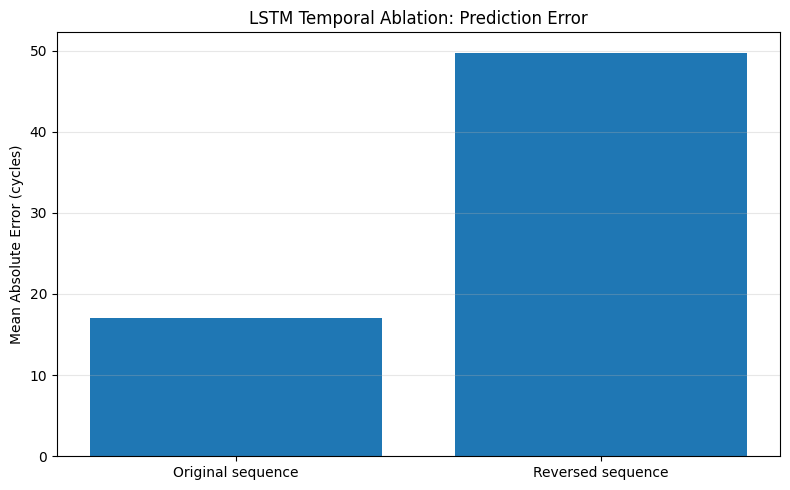

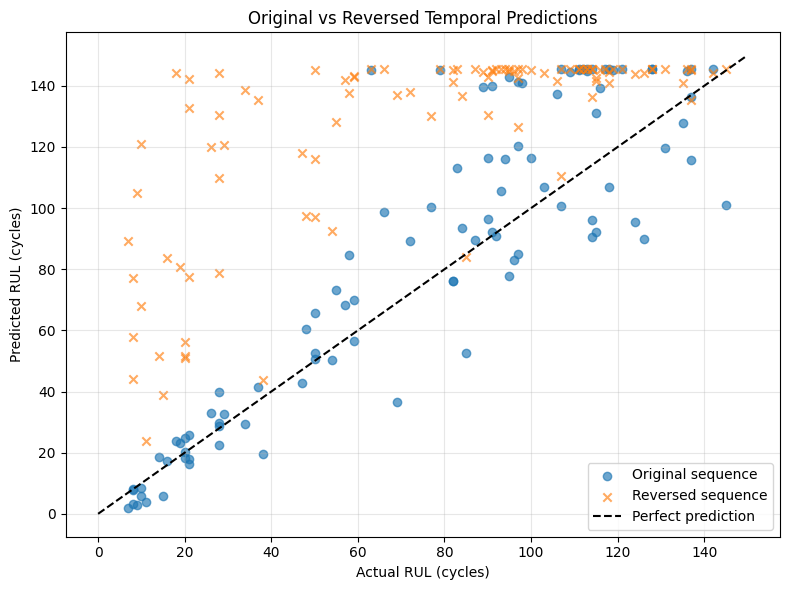


PREDICTION SENSITIVITY TO TEMPORAL ORDER
Mean absolute prediction change: 41.4488 cycles
Maximum prediction change: 120.3324 cycles


In [ ]:

# ============================================================
# PART B — CELL 7: TEMPORAL ABLATION EXPERIMENT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Original chronological test sequences
X_original = X_test_seq.copy()

# 2. Reverse the chronological order of all 30 cycles
X_reversed = X_test_seq[:, ::-1, :].copy()

# 3. Predict using the SAME trained LSTM
pred_original = lstm_model.predict(
    X_original, verbose=0
).flatten()

pred_reversed = lstm_model.predict(
    X_reversed, verbose=0
).flatten()

# RUL cannot be negative
pred_original = np.maximum(pred_original, 0)
pred_reversed = np.maximum(pred_reversed, 0)

# 4. Evaluation function
def evaluate_rul(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "R2": r2_score(actual, predicted)
    }

original_metrics = evaluate_rul(y_test, pred_original)
reversed_metrics = evaluate_rul(y_test, pred_reversed)

# 5. Comparison table
comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Original": [
        original_metrics["MAE"],
        original_metrics["RMSE"],
        original_metrics["R2"]
    ],
    "Reversed": [
        reversed_metrics["MAE"],
        reversed_metrics["RMSE"],
        reversed_metrics["R2"]
    ]
})

comparison["Change (Reversed - Original)"] = (
    comparison["Reversed"] - comparison["Original"]
)

print("=" * 65)
print("PART B — TEMPORAL ABLATION RESULTS")
print("=" * 65)

display(comparison.round(4))

# 6. Plot comparison of prediction errors
plt.figure(figsize=(8, 5))

plt.bar(
    ["Original sequence", "Reversed sequence"],
    [
        original_metrics["MAE"],
        reversed_metrics["MAE"]
    ]
)

plt.ylabel("Mean Absolute Error (cycles)")
plt.title("LSTM Temporal Ablation: Prediction Error")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Compare predictions directly
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    pred_original,
    alpha=0.65,
    label="Original sequence"
)

plt.scatter(
    y_test,
    pred_reversed,
    alpha=0.65,
    marker="x",
    label="Reversed sequence"
)

plt.plot(
    [0, 150],
    [0, 150],
    "k--",
    label="Perfect prediction"
)

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Original vs Reversed Temporal Predictions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Quantify changes in individual predictions
prediction_change = np.abs(
    pred_original - pred_reversed
)

print("\nPREDICTION SENSITIVITY TO TEMPORAL ORDER")
print(
    f"Mean absolute prediction change: "
    f"{prediction_change.mean():.4f} cycles"
)
print(
    f"Maximum prediction change: "
    f"{prediction_change.max():.4f} cycles"
)


### Temporal Ablation Analysis

Reversing the chronological order of sensor measurements increased test MAE from 17.07 to 49.76 cycles and reduced R² from 0.6884 to −0.9464. This substantial deterioration demonstrates that the trained LSTM is sensitive to temporal ordering rather than relying exclusively on unordered sensor values. However, sequence reversal creates an artificial input distribution, so the experiment does not independently establish that the model has learned physically meaningful degradation dynamics.


These findings support the importance of temporal ordering in the LSTM's predictions and are consistent with the model learning useful sequential degradation information. However, because reversed sequences differ from the training distribution, the experiment does not independently establish which physical degradation mechanisms were learned.

PART B — BASELINE VS LSTM

Baseline constant prediction: 94.75 cycles


,Model,MAE,RMSE,R2
0,Mean RUL Baseline,36.6155,45.7905,-0.2142
1,LSTM,17.0698,23.1954,0.6884



LSTM MAE improvement over baseline: 53.38%


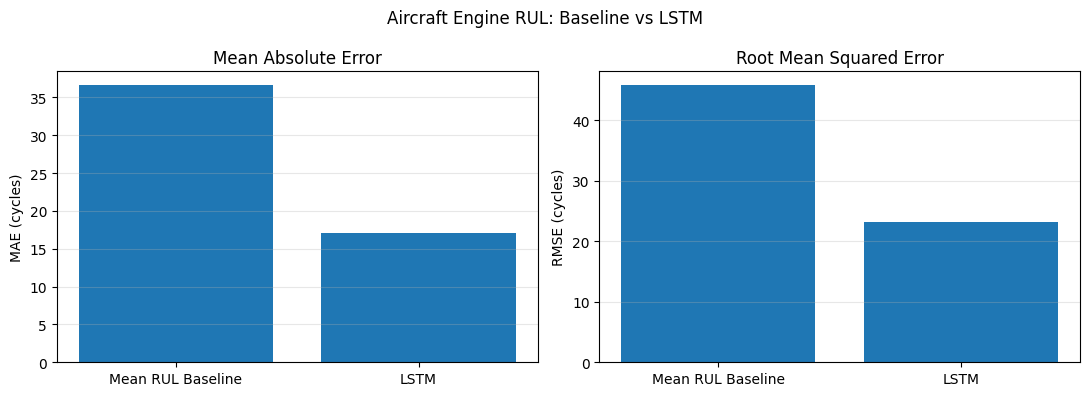

In [ ]:

# ============================================================
# PART B — CELL 8: BASELINE VS LSTM COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Baseline: mean training RUL at the final window
#    of each training engine.
#
#    This is an engine-level constant baseline.

train_last_window_rul = []

for engine_id, group in train_part.groupby("engine_id"):
    group = group.sort_values("cycle")

    # RUL at the final available cycle
    train_last_window_rul.append(
        group["RUL"].iloc[-1]
    )

# NOTE:
# Complete training engines end at failure, so their
# final RUL is always zero. A constant-zero baseline
# would not provide a meaningful mean-life reference.
#
# Instead, use the mean RUL of the training windows,
# which contains observations at different life stages.

baseline_rul = float(np.mean(y_train_seq))

# Constant prediction for all 100 test engines
y_baseline = np.full(
    shape=len(y_test),
    fill_value=baseline_rul,
    dtype=np.float32
)

# 2. Existing LSTM predictions
y_lstm = np.maximum(
    lstm_model.predict(
        X_test_seq,
        verbose=0
    ).flatten(),
    0
)

# 3. Evaluation function
def evaluate_model(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred)
    }

baseline_metrics = evaluate_model(y_test, y_baseline)
lstm_metrics = evaluate_model(y_test, y_lstm)

# 4. Comparison table
baseline_comparison = pd.DataFrame({
    "Model": ["Mean RUL Baseline", "LSTM"],
    "MAE": [
        baseline_metrics["MAE"],
        lstm_metrics["MAE"]
    ],
    "RMSE": [
        baseline_metrics["RMSE"],
        lstm_metrics["RMSE"]
    ],
    "R2": [
        baseline_metrics["R2"],
        lstm_metrics["R2"]
    ]
})

print("=" * 65)
print("PART B — BASELINE VS LSTM")
print("=" * 65)

print(
    f"\nBaseline constant prediction: "
    f"{baseline_rul:.2f} cycles"
)

display(baseline_comparison.round(4))

# 5. Percentage improvement in MAE
mae_improvement = (
    (baseline_metrics["MAE"] - lstm_metrics["MAE"])
    / baseline_metrics["MAE"]
) * 100

print(
    f"\nLSTM MAE improvement over baseline: "
    f"{mae_improvement:.2f}%"
)

# 6. Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

models = baseline_comparison["Model"]

axes[0].bar(
    models,
    baseline_comparison["MAE"]
)

axes[0].set_title("Mean Absolute Error")
axes[0].set_ylabel("MAE (cycles)")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    models,
    baseline_comparison["RMSE"]
)

axes[1].set_title("Root Mean Squared Error")
axes[1].set_ylabel("RMSE (cycles)")
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle("Aircraft Engine RUL: Baseline vs LSTM")
plt.tight_layout()
plt.show()


### Baseline Comparison: Mean RUL Predictor vs LSTM

### Baseline Comparison

The LSTM substantially outperformed the training-window mean RUL baseline, reducing test MAE from 36.62 to 17.07 cycles (53.38% improvement) and RMSE from 45.79 to 23.20 cycles. The LSTM achieved an R² of 0.6884 compared with −0.2142 for the baseline, demonstrating that temporal sensor modelling provides considerably greater predictive accuracy than a constant RUL estimate.

Overall, the LSTM provides meaningful predictive improvements over a constant RUL estimate, strengthening the justification for recurrent modelling in this task.

###OVERALL SUMMARY FROM PART A-PART B

### Overall Summary and Conclusion

This assignment investigated representation learning and temporal prediction using two real-world datasets.

**Part A — Representation Learning:** PCA and a linear autoencoder were applied to industrial sensor data. The first two principal components explained 59.06% of total variance, while PCA loading analysis identified contributions from both binary operational states and continuous sensor measurements. Subspace analysis demonstrated substantial agreement between PCA and the autoencoder (mean squared cosine similarity = 0.8423). Increasing autoencoder latent dimensions from 2 to 5 reduced validation reconstruction MSE from 0.5373 to 0.4243.

**Part B — Remaining Useful Life Prediction:** An LSTM was developed using NASA C-MAPSS FD001 engine data. The baseline model achieved a test MAE of 17.07 cycles, RMSE of 23.20 cycles and R² of 0.6884, reducing MAE by 53.38% relative to a constant mean-RUL baseline. Residual analysis identified stronger prediction accuracy near failure and systematic overestimation at intermediate RUL values. Temporal reversal increased MAE to 49.76 cycles, demonstrating sensitivity to sequence ordering.

**Sensitivity Analysis:** Controlled experiments showed lower validation errors with 128 LSTM units, a learning rate of 0.002 and a 40-cycle window compared with their respective baseline settings. These improvements were observed independently and do not establish an optimal combined configuration.

**Conclusion:** The findings demonstrate the usefulness of dimensionality reduction for sensor representation and recurrent neural networks for predictive maintenance. They also highlight the importance of feature interpretation, temporal structure, hyperparameter sensitivity and critical evaluation of model limitations.